In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Configuration et entrainement des modèles yolov5 et yolov8
1. Entrainement de yolov8 avec le dataset cityscapes
2. Entrainement de yolov5 avec le dataset cityscapes
3. Entrainement de yolov8 avec notre dataset


In [ ]:
!pip install ultralytics

In [ ]:
!pip install tensorboard

1. Entrainement de yolov8 avec le dataset cityscapes

In [ ]:
import os
import json

def convert_polygon_to_bbox(polygon):
    x_coords = [point[0] for point in polygon]
    y_coords = [point[1] for point in polygon]
    return [min(x_coords), min(y_coords), max(x_coords), max(y_coords)]

def create_yolo_annotation(img_height, img_width, objects):
    yolo_annotations = []
    for obj in objects:
        label = obj['label']
        if label not in ['person', 'rider']:
            continue
        bbox = convert_polygon_to_bbox(obj['polygon'])
        x_center = (bbox[0] + bbox[2]) / 2.0 / img_width
        y_center = (bbox[1] + bbox[3]) / 2.0 / img_height
        width = (bbox[2] - bbox[0]) / img_width
        height = (bbox[3] - bbox[1]) / img_height
        label_id = 0 if label == 'person' else 1
        yolo_annotations.append(f"{label_id} {x_center} {y_center} {width} {height}")
    return yolo_annotations

train_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen'
val_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster'

def process_cityscapes_annotations(directory):
    for root, _, files in os.walk(directory):
        for file in files:
            if file.endswith('_polygons.json'):
                json_path = os.path.join(root, file)
                with open(json_path, 'r') as f:
                    data = json.load(f)
                img_height = data['imgHeight']
                img_width = data['imgWidth']
                objects = data['objects']
                yolo_annotations = create_yolo_annotation(img_height, img_width, objects)
                if yolo_annotations:
                    txt_path = json_path.replace('_polygons.json', '.txt')
                    with open(txt_path, 'w') as f:
                        f.write('\n'.join(yolo_annotations))

process_cityscapes_annotations(train_dir)
process_cityscapes_annotations(val_dir)


In [ ]:
import os

def list_txt_files(directory):
    txt_files = []
    for root, _, files in os.walk(directory):
        for file in files:
            if file.endswith('.txt'):
                txt_files.append(os.path.join(root, file))
    return txt_files

# Lister quelques fichiers .txt dans les répertoires d'entraînement et de validation
train_txt_files = list_txt_files(train_dir)
val_txt_files = list_txt_files(val_dir)

print("Fichiers d'annotations d'entraînement (quelques exemples) :")
print(train_txt_files[:5])

print("\nFichiers d'annotations de validation (quelques exemples) :")
print(val_txt_files[:5])


Fichiers d'annotations d'entraînement (quelques exemples) :
['/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen/bremen_000012_000019_gtFine.txt', '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen/bremen_000227_000019_gtFine.txt', '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen/bremen_000298_000019_gtFine.txt', '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen/bremen_000059_000019_gtFine.txt', '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen/bremen_000052_000019_gtFine.txt']

Fichiers d'annotations de validation (quelques exemples) :
['/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster/munster_000110_000019_gtFine.txt', '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster/munster_000024_000019_gtFine.txt', '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster/munster_000106_000019_gtFine.txt', '/cont

In [ ]:
def display_txt_content(file_path, num_lines=5):
    with open(file_path, 'r') as f:
        lines = f.readlines()
    print(f"Contenu de {file_path} :")
    for line in lines[:num_lines]:
        print(line.strip())

if train_txt_files:
    display_txt_content(train_txt_files[0])

if val_txt_files:
    display_txt_content(val_txt_files[0])


Contenu de /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen/bremen_000012_000019_gtFine.txt :
0 0.09814453125 0.427734375 0.0078125 0.041015625
0 0.1279296875 0.42919921875 0.0078125 0.0419921875
1 0.117431640625 0.43017578125 0.01416015625 0.0400390625
0 0.22412109375 0.4375 0.0107421875 0.076171875
0 0.213623046875 0.44287109375 0.01513671875 0.0615234375
Contenu de /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster/munster_000110_000019_gtFine.txt :
0 0.355712890625 0.42578125 0.00830078125 0.02734375


In [ ]:
# Créer le fichier YAML de configuration du dataset
custom = """
train: /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen
val: /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster

nc: 2  # Nombre de classes (personne et personne sur un vélo)
names: [ 'pedestrian', 'rider' ]
"""

# Give a filename to the YAML configuration file.
custom_path = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/data/my_dataset.yaml'

with open(custom_path, 'w') as file:
    file.write(custom)

print("Fichier de configuration YAML créé.")

Fichier de configuration YAML créé.


In [ ]:
from ultralytics import YOLO

# Charger le modèle YOLOv8 pré-entraîné
model = YOLO('yolov8n.pt')

# Entraîner le modèle
model.train(data='/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/data/my_dataset.yaml', epochs=1, imgsz=640)


100%|██████████| 6.25M/6.25M [00:00<00:00, 77.8MB/s]


Ultralytics YOLOv8.2.54 🚀 Python-3.10.12 torch-2.3.0+cpu CPU (Intel Xeon 2.00GHz)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/data/my_dataset.yaml, epochs=1, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=Fals

100%|██████████| 755k/755k [00:00<00:00, 14.8MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytics

train: Scanning /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen.cache... 0 images, 948 backgrounds, 0 corrupt: 100%|██████████| 948/948 [00:00<?, ?it/s]

WARNING ⚠️ No labels found in /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen.cache, training may not work correctly. See https://docs.ultralytics.com/datasets for dataset formatting guidance.


... (6 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:57<00:00,  3.37s/it]

                   all        522          0          0          0          0          0
WARNING ⚠️ no labels found in detect set, can not compute metrics without labels


Speed: 1.2ms preprocess, 77.3ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to runs/detect/train


AttributeError: 'DetMetrics' object has no attribute 'curves_results'. See valid attributes below.

    This class is a utility class for computing detection metrics such as precision, recall, and mean average precision
    (mAP) of an object detection model.

    Args:
        save_dir (Path): A path to the directory where the output plots will be saved. Defaults to current directory.
        plot (bool): A flag that indicates whether to plot precision-recall curves for each class. Defaults to False.
        on_plot (func): An optional callback to pass plots path and data when they are rendered. Defaults to None.
        names (tuple of str): A tuple of strings that represents the names of the classes. Defaults to an empty tuple.

    Attributes:
        save_dir (Path): A path to the directory where the output plots will be saved.
        plot (bool): A flag that indicates whether to plot the precision-recall curves for each class.
        on_plot (func): An optional callback to pass

2. Entrainement de yolov5 avec le dataset cityscapes

In [ ]:
# Installation des dépendances
!pip install -q torch torchvision torchaudio
!pip install -q yolov5

# Cloner le dépôt YOLOv5 et installation des dépendances
!git clone https://github.com/ultralytics/yolov5
%cd yolov5
!pip install -qr requirements.txt

In [ ]:
import os
import json
import numpy as np
from PIL import Image, ImageDraw
import shutil

def create_mask_from_polygon(polygon, img_shape):
    polygon = [(int(x), int(y)) for x, y in polygon]
    mask = Image.new('L', (img_shape[1], img_shape[0]), 0)
    ImageDraw.Draw(mask).polygon(polygon, outline=1, fill=1)
    return np.array(mask)

def convert_annotations(instance_img_path, json_path, output_dir, class_map):
    with open(json_path) as f:
        instances = json.load(f)['objects']

    height, width = 1024, 2048
    annotation_path = os.path.join(output_dir, os.path.basename(instance_img_path).replace('_gtFine_instanceIds.png', '.txt'))

    with open(annotation_path, 'w') as f:
        for instance in instances:
            class_name = instance['label']
            if class_name in class_map:
                class_id = class_map[class_name]
                polygon = instance['polygon']
                mask = create_mask_from_polygon(polygon, (height, width))
                y_indices, x_indices = np.where(mask)
                if len(y_indices) == 0 or len(x_indices) == 0:
                    continue
                x_min, x_max = x_indices.min(), x_indices.max()
                y_min, y_max = y_indices.min(), y_indices.max()
                x_center = (x_min + x_max) / 2.0 / width
                y_center = (y_min + y_max) / 2.0 / height
                bbox_width = (x_max - x_min) / width
                bbox_height = (y_max - y_min) / height
                f.write(f"{class_id} {x_center:.6f} {y_center:.6f} {bbox_width:.6f} {bbox_height:.6f}\n")
                print(f"Annotation written: {annotation_path}")

    # Copier l'image dans le répertoire de sortie
    image_path = instance_img_path.replace('_gtFine_instanceIds.png', '_gtFine_color.png')
    if os.path.exists(image_path):
        shutil.copy(image_path, os.path.join(output_dir, os.path.basename(image_path)))
        print(f"Image copied: {image_path}")

# Chemins des répertoires
train_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest/gtFine/train'
val_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest/gtFine/val'
test_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest/gtFine/test'
output_train_dir = '/content/yolo_annotations/train'
output_val_dir = '/content/yolo_annotations/val'
output_test_dir = '/content/yolo_annotations/test'
os.makedirs(output_train_dir, exist_ok=True)
os.makedirs(output_val_dir, exist_ok=True)
os.makedirs(output_test_dir, exist_ok=True)

# Mapping des classes
class_map = {'person': 0, 'rider': 1}

# Conversion des annotations pour train, val et test
def convert_directory(input_dir, output_dir, class_map):
    for city in os.listdir(input_dir):
        city_dir = os.path.join(input_dir, city)
        if os.path.isdir(city_dir):
            for file in os.listdir(city_dir):
                if file.endswith('_gtFine_instanceIds.png'):
                    instance_img_path = os.path.join(city_dir, file)
                    json_path = instance_img_path.replace('_gtFine_instanceIds.png', '_gtFine_polygons.json')
                    convert_annotations(instance_img_path, json_path, output_dir, class_map)
                    print(f"Processed: {instance_img_path}")

convert_directory(train_dir, output_train_dir, class_map)
convert_directory(val_dir, output_val_dir, class_map)
convert_directory(test_dir, output_test_dir, class_map)

def list_files(dir_path):
    for root, dirs, files in os.walk(dir_path):
        for file in files:
            print(os.path.join(root, file))

print("Fichiers dans le répertoire d'entraînement:")
list_files(output_train_dir)

print("Fichiers dans le répertoire de validation:")
list_files(output_val_dir)

print("Fichiers dans le répertoire de test:")
list_files(output_test_dir)


Streaming output truncated to the last 5000 lines.
/content/yolo_annotations/train/stuttgart_000139_000019.txt
/content/yolo_annotations/train/stuttgart_000162_000019_gtFine_color.png
/content/yolo_annotations/train/bremen_000302_000019.txt
/content/yolo_annotations/train/tubingen_000066_000019_gtFine_color.png
/content/yolo_annotations/train/dusseldorf_000117_000019_gtFine_color.png
/content/yolo_annotations/train/zurich_000046_000019_gtFine_color.png
/content/yolo_annotations/train/monchengladbach_000000_033454.txt
/content/yolo_annotations/train/stuttgart_000184_000019.txt
/content/yolo_annotations/train/dusseldorf_000207_000019.txt
/content/yolo_annotations/train/darmstadt_000051_000019.txt
/content/yolo_annotations/train/cologne_000135_000019.txt
/content/yolo_annotations/train/cologne_000095_000019.txt
/content/yolo_annotations/train/hamburg_000000_089491.txt
/content/yolo_annotations/train/hanover_000000_047629.txt
/content/yolo_annotations/train/aachen_000071_000019.txt
/conten

In [ ]:
import os
import glob

# Vérification des fichiers de labels
def check_labels_files(label_dir):
    label_files = glob.glob(os.path.join(label_dir, '*.txt'))
    if len(label_files) == 0:
        print(f"Erreur : Aucun fichier de labels trouvé dans {label_dir}")
    else:
        print(f"OK : {len(label_files)} fichiers de labels trouvés dans {label_dir}")
        # Affichage du contenu de quelques fichiers de labels pour vérifier les annotations
        for file_path in label_files[:5]:  # Vérifiez les 5 premiers fichiers de labels
            print(f"Contenu du fichier {file_path}:")
            with open(file_path, 'r') as f:
                print(f.read())

# Vérification des chemins et des fichiers d'étiquettes
def check_config_paths(config_path):
    with open(config_path, 'r') as f:
        config = f.readlines()

    paths = ['train', 'val']
    for line in config:
        for path in paths:
            if line.startswith(f'{path}:'):
                data_path = line.split(': ')[1].strip()
                if not os.path.exists(data_path):
                    print(f"Erreur : Le chemin {data_path} dans le fichier de configuration n'existe pas.")
                else:
                    print(f"OK : Le chemin {data_path} dans le fichier de configuration existe.")

# Regénération du cache des labels
def regenerate_labels_cache(labels_dir):
    cache_path = os.path.join(labels_dir, 'train.cache')
    if os.path.exists(cache_path):
        os.remove(cache_path)
        print(f"Cache des labels supprimé : {cache_path}")
    else:
        print(f"Cache des labels non trouvé : {cache_path}")
    print("Le cache des labels sera régénéré lors du prochain entraînement.")

# Chemins des répertoires et fichiers
base_dir = '/content/drive/MyDrive/projet/yolov5_cityscapes'
train_label_dir = os.path.join(base_dir, 'labels/train')
config_path = os.path.join(base_dir, 'cityscapes.yaml')

# Exécution des vérifications et corrections
check_labels_files(train_label_dir)
check_config_paths(config_path)
regenerate_labels_cache(train_label_dir)


OK : 174 fichiers de labels trouvés dans /content/drive/MyDrive/projet/yolov5_cityscapes/labels/train
Contenu du fichier /content/drive/MyDrive/projet/yolov5_cityscapes/labels/train/aachen_000062_000019_gtFine.txt:
0 0.611083984375 0.5048828125 0.01123046875 0.060546875
0 0.537109375 0.49560546875 0.005859375 0.0107421875
0 0.464599609375 0.505859375 0.00341796875 0.017578125
1 0.370849609375 0.5078125 0.00341796875 0.013671875

Contenu du fichier /content/drive/MyDrive/projet/yolov5_cityscapes/labels/train/aachen_000023_000019_gtFine.txt:
0 0.458251953125 0.443359375 0.00927734375 0.06640625
0 0.469482421875 0.44677734375 0.02001953125 0.1025390625
0 0.485595703125 0.4482421875 0.01904296875 0.09765625
0 0.372802734375 0.45361328125 0.01708984375 0.1220703125
0 0.3857421875 0.4599609375 0.029296875 0.173828125
0 0.345703125 0.4755859375 0.0380859375 0.263671875
0 0.20068359375 0.47314453125 0.0390625 0.2021484375

Contenu du fichier /content/drive/MyDrive/projet/yolov5_cityscapes/labe

In [ ]:
# Créer le fichier YAML de configuration du dataset
data_yaml_content = """
train: /content/yolo_annotations/train
val: /content/yolo_annotations/val

nc: 2  # Nombre de classes (personne et personne sur un vélo)
names: [ 'person', 'rider' ]
"""

data_yaml_path = '/content/yolo_annotations/data.yaml'

with open(data_yaml_path, 'w') as file:
    file.write(data_yaml_content)

print("Fichier de configuration YAML créé.")

Fichier de configuration YAML créé.


In [ ]:
# Lancer l'entraînement de YOLOv5
!python train.py --img 640 --batch 16 --epochs 50 --data {data_yaml_path} --cfg yolov5s.yaml --weights yolov5s.pt

train: weights=yolov5s.pt, cfg=yolov5s.yaml, data=/content/yolo_annotations/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=50, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=exp, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1, artifact_alias=latest, ndjson_console=False, ndjson_file=False
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-330-gb20fa802 Python-3.10.12 torch-2.3.0+cpu CPU

hyperparameters: lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=0.0005, warmup_epochs=3.0, warmup_momentum=0.8, warmup_bias_lr=0.1, box=0.05, cls=0.5, cls_pw

In [ ]:
import os

# Chemins des répertoires
images_dir = '/content/drive/MyDrive/projet/yolov5_cityscapes/images/train'
labels_dir = '/content/drive/MyDrive/projet/yolov5_cityscapes/labels/train'

# Obtention des listes de fichiers
image_files = sorted([os.path.splitext(f)[0] for f in os.listdir(images_dir) if f.endswith('.png')])
label_files = sorted([os.path.splitext(f)[0] for f in os.listdir(labels_dir) if f.endswith('.txt')])

# Vérification des correspondances
for image_file in image_files:
    if image_file not in label_files:
        print(f"Erreur : Pas de label correspondant pour l'image {image_file}.png")

print("Vérification des correspondances terminée.")


Erreur : Pas de label correspondant pour l'image aachen_000000_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000001_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000002_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000003_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000004_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000005_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000006_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000007_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000008_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000009_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'image aachen_000010_000019_gtFine_color.png
Erreur : Pas de label correspondant pour l'

Nous n'avons malheureusement pas été capable d'entrainer correctement ni yolov5 ni yolov8 sur nos données.

Après investigation des problèmes techniques rencontrés à travers plusieurs essais avec différents sous-répertoires de données du dataset, il en ressort que nos données ne sont pas adaptés à l'utilisation ni de yolov5 ni de yolov8. Les modèles yolo nécessitent des bounding boxes tandis que nos annotations dans les fichiers JSON sont des polygons et la conversion de ces polygones en bounding boxes provoque une incompatibilité er incohérence des nouvelles annotations et des objets cibles (person et rider).

Nous entrainons donc yolov8 dans la section suivante mais avec un dataset crée par nous mêmes constitué de 60 images d'entrainemnt et 15 de validation annotées manuellement avec CVAT

3. Entrainement de yolov8 avec notre dataset

In [ ]:
import os
from ultralytics import YOLO

# Définition du répertoire racine (ROOT_DIR)
ROOT_DIR = '/content/drive/MyDrive/projet/yolov8'

# Définition des chemins pour les données et les logs de TensorBoard
data_config = os.path.join(ROOT_DIR, "data.yaml")
tb_log_dir = os.path.join(ROOT_DIR, "runs/train")

# Chargement un modèle YOLOv8 pré-entraîné
model = YOLO("yolov8n.yaml")

# Spécification du batch_size
batch_size = 8

# Lancement de l'entraînement avec le batch_size spécifié
results = model.train(
    data=data_config,
    epochs=250,
    project=tb_log_dir,  # Répertoire pour les logs et les résultats d'entraînement
    name='exp',  # Nom de l'expérience
    batch=batch_size,
)

print("Entraînement terminé. Les logs de TensorBoard sont enregistrés dans :", tb_log_dir)


Ultralytics YOLOv8.2.54 🚀 Python-3.10.12 torch-2.3.0+cpu CPU (Intel Xeon 2.00GHz)
engine/trainer: task=detect, mode=train, model=yolov8n.yaml, data=/content/drive/MyDrive/projet/yolov8/data.yaml, epochs=250, time=None, patience=100, batch=8, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=/content/drive/MyDrive/projet/yolov8/runs/train, name=exp8, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=Fals

train: Scanning /content/drive/MyDrive/projet/yolov8/labels/train.cache... 60 images, 0 backgrounds, 0 corrupt: 100%|██████████| 60/60 [00:00<?, ?it/s]
val: Scanning /content/drive/MyDrive/projet/yolov8/labels/val.cache... 15 images, 0 backgrounds, 0 corrupt: 100%|██████████| 15/15 [00:00<?, ?it/s]

Plotting labels to /content/drive/MyDrive/projet/yolov8/runs/train/exp8/labels.jpg... 


optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.001667, momentum=0.9) with parameter groups 57 weight(decay=0.0), 64 weight(decay=0.0005), 63 bias(decay=0.0)
TensorBoard: model graph visualization added ✅
Image sizes 640 train, 640 val
Using 0 dataloader workers
Logging results to /content/drive/MyDrive/projet/yolov8/runs/train/exp8
Starting training for 250 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/250         0G      4.279      4.143      4.327         41        640: 100%|██████████| 8/8 [00:34<00:00,  4.26s/it]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:02<00:00,  2.66s/it]

                   all         15         92    0.00388      0.159     0.0103     0.0024


... (746 outputs left out)

                   all         15         92      0.766       0.51      0.681      0.351



250 epochs completed in 2.177 hours.
Optimizer stripped from /content/drive/MyDrive/projet/yolov8/runs/train/exp8/weights/last.pt, 6.3MB
Optimizer stripped from /content/drive/MyDrive/projet/yolov8/runs/train/exp8/weights/best.pt, 6.3MB

Validating /content/drive/MyDrive/projet/yolov8/runs/train/exp8/weights/best.pt...
Ultralytics YOLOv8.2.54 🚀 Python-3.10.12 torch-2.3.0+cpu CPU (Intel Xeon 2.00GHz)
YOLOv8n summary (fused): 168 layers, 3006038 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:02<00:00,  2.05s/it]


                   all         15         92      0.831      0.536      0.685      0.377
            pedestrian         11         69      0.747      0.377      0.592      0.339
                 rider         10         23      0.914      0.696      0.778      0.414
Speed: 1.7ms preprocess, 114.0ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to /content/drive/MyDrive/projet/yolov8/runs/train/exp8
Entraînement terminé. Les logs de TensorBoard sont enregistrés dans : /content/drive/MyDrive/projet/yolov8/runs/train


# Approche avec le modèle EfficientNetB0 comme base plus deux têtes (une pour la classification et l'autre pour la régression)


In [ ]:
import tensorflow as tf
import numpy as np
import os
import json
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Input, Conv2D, Dense, Flatten, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from sklearn.metrics import recall_score, f1_score

# Chemins des répertoires de données
train_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train'
val_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster'

# Préparation des données
def load_data(root_dir, target_labels):
    images = []
    bboxes = []
    for subdir, _, files in os.walk(root_dir):
        for file in files:
            if file.endswith('_gtFine_color.png'):
                image_path = os.path.join(subdir, file)
                json_path = image_path.replace('_color.png', '_polygons.json')

                image = cv2.imread(image_path)
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

                if not os.path.exists(json_path):
                    print(f"JSON file not found: {json_path}")
                    continue

                with open(json_path) as f:
                    try:
                        data = json.load(f)
                    except json.JSONDecodeError:
                        print(f"Error reading JSON file: {json_path}")
                        continue

                img_height = data.get('imgHeight')
                img_width = data.get('imgWidth')

                if img_height is None or img_width is None:
                    print(f"Invalid JSON structure in file: {json_path}")
                    continue

                boxes = []
                for obj in data.get('objects', []):
                    if obj.get('label') in target_labels:
                        polygon = np.array(obj.get('polygon', []))
                        if len(polygon) == 0:
                            continue
                        x_min = np.min(polygon[:, 0])
                        x_max = np.max(polygon[:, 0])
                        y_min = np.min(polygon[:, 1])
                        y_max = np.max(polygon[:, 1])
                        boxes.append([x_min, y_min, x_max, y_max, target_labels.index(obj['label'])])

                if len(boxes) > 0:
                    images.append(image)
                    bboxes.append(boxes)

    return images, bboxes

target_labels = ['person', 'rider']
train_images, train_bboxes = load_data(train_dir, target_labels)
val_images, val_bboxes = load_data(val_dir, target_labels)

print(f"Number of training images: {len(train_images)}")
print(f"Number of validation images: {len(val_images)}")
print(f"Number of training bounding boxes: {len(train_bboxes)}")
print(f"Number of validation bounding boxes: {len(val_bboxes)}")
print(f"Number of target labels: {len(target_labels)}")

# Prétraitement des données
def preprocess_data(images, bboxes, target_size):
    images_resized = []
    bboxes_resized = []

    for img, bbox in zip(images, bboxes):
        h, w, _ = img.shape
        img_resized = cv2.resize(img, (target_size[1], target_size[0]))

        scale_x = target_size[1] / w
        scale_y = target_size[0] / h

        bbox_resized = []
        for box in bbox:
            x_min, y_min, x_max, y_max, label = box
            x_min = int(x_min * scale_x)
            y_min = int(y_min * scale_y)
            x_max = int(x_max * scale_x)
            y_max = int(y_max * scale_y)
            bbox_resized.append([x_min, y_min, x_max, y_max, label])

        images_resized.append(img_resized)
        bboxes_resized.append(bbox_resized)

    images_resized = np.array(images_resized) / 255.0
    return images_resized, bboxes_resized

target_size = (224, 224)
train_images, train_bboxes = preprocess_data(train_images, train_bboxes, target_size)
val_images, val_bboxes = preprocess_data(val_images, val_bboxes, target_size)

Error reading JSON file: /content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/darmstadt/darmstadt_000014_000019_gtFine_polygons.json
Number of training images: 2489
Number of validation images: 160
Number of training bounding boxes: 2489
Number of validation bounding boxes: 160
Number of target labels: 2


In [ ]:
def build_simple_model(input_shape, num_classes):
    base_model = EfficientNetB0(include_top=False, input_shape=input_shape, weights='imagenet')
    base_model.trainable = True

    inputs = Input(shape=input_shape)
    feature_map = base_model(inputs)

    x_class = Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001))(feature_map)
    x_class = Dropout(0.3)(x_class)
    x_class = GlobalAveragePooling2D()(x_class)
    classification_output = Dense(num_classes, activation='softmax', kernel_regularizer=l2(0.001), name='classification')(x_class)

    x_regress = Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001))(feature_map)
    x_regress = Dropout(0.3)(x_regress)
    x_regress = GlobalAveragePooling2D()(x_regress)
    regression_output = Dense(num_classes * 4, kernel_regularizer=l2(0.001), name='regression')(x_regress)

    model = Model(inputs, [classification_output, regression_output])
    return model

input_shape = (target_size[0], target_size[1], 3)
num_classes = len(target_labels)

model = build_simple_model(input_shape, num_classes)
model.compile(optimizer=Adam(learning_rate=1e-5), loss={'classification': 'categorical_crossentropy', 'regression': 'mse'}, metrics={'classification': 'accuracy'}, run_eagerly=True)
model.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_4 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 efficientnetb0 (Functional  (None, 7, 7, 1280)           4049571   ['input_4[0][0]']             
 )                                                                                                
                                                                                                  
 conv2d_2 (Conv2D)           (None, 7, 7, 128)            1474688   ['efficientnetb0[0][0]']      
                                                                                                  
 conv2d_3 (Conv2D)           (None, 7, 7, 128)            1474688   ['efficientnetb0[0][0]']

In [ ]:
def generator(images, bboxes, batch_size, num_classes):
    while True:
        batch_images = np.zeros((batch_size, target_size[0], target_size[1], 3))
        y_class = np.zeros((batch_size, num_classes))
        y_regress = np.zeros((batch_size, num_classes * 4))

        for i in range(batch_size):
            idx = np.random.randint(0, len(images))
            batch_images[i] = images[idx]
            for box in bboxes[idx]:
                x_min, y_min, x_max, y_max, label = box
                y_class[i, int(label)] = 1
                y_regress[i, int(label)*4:int(label)*4+4] = [x_min, y_min, x_max, y_max]

        yield batch_images, {'classification': y_class, 'regression': y_regress}

batch_size = 64
train_gen = generator(train_images, train_bboxes, batch_size, num_classes)
val_gen = generator(val_images, val_bboxes, batch_size, num_classes)

In [ ]:
callbacks = [
    EarlyStopping(patience=20, restore_best_weights=True),
    ReduceLROnPlateau(patience=15)
]

history = model.fit(
    train_gen,
    steps_per_epoch=len(train_images) // batch_size,
    validation_data=val_gen,
    validation_steps=len(val_images) // batch_size,
    epochs=100,
    callbacks=callbacks
)

results = model.evaluate(val_gen, steps=len(val_images) // batch_size)
print(f'Validation Loss: {results[0]}')
print(f'Validation Classification Loss: {results[1]}')
print(f'Validation Regression Loss: {results[2]}')
print(f'Validation Classification Accuracy: {results[3]}')

Epoch 1/100
38/38 [==============================] - 150s 4s/step - loss: 8679.5703 - classification_loss: 0.8680 - regression_loss: 8678.2207 - classification_accuracy: 0.9301 - val_loss: 9207.8047 - val_classification_loss: 1.0106 - val_regression_loss: 9206.3105 - val_classification_accuracy: 0.8047 - lr: 1.0000e-05
Epoch 2/100
38/38 [==============================] - 151s 4s/step - loss: 8547.5518 - classification_loss: 0.8684 - regression_loss: 8546.2002 - classification_accuracy: 0.9363 - val_loss: 10661.0762 - val_classification_loss: 1.0950 - val_regression_loss: 10659.4980 - val_classification_accuracy: 0.8594 - lr: 1.0000e-05
Epoch 3/100
38/38 [==============================] - 151s 4s/step - loss: 7992.0171 - classification_loss: 0.8600 - regression_loss: 7990.6743 - classification_accuracy: 0.9330 - val_loss: 10704.4668 - val_classification_loss: 1.1360 - val_regression_loss: 10702.8457 - val_classification_accuracy: 0.8047 - lr: 1.0000e-05
Epoch 4/100
38/38 [==============

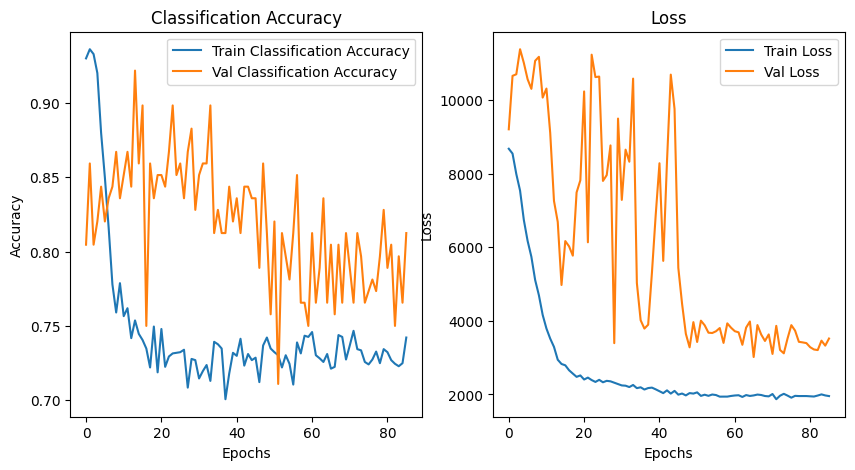

In [ ]:
# Affichage des courbes des métriques de performances
def plot_metrics(history):
    plt.figure(figsize=(10, 5))

    # Plot classification accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['classification_accuracy'], label='Train Classification Accuracy')
    plt.plot(history.history['val_classification_accuracy'], label='Val Classification Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.title('Classification Accuracy')

    # Plot loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.title('Loss')

    plt.show()

plot_metrics(history)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Affichage des résultats
def display_results(images, bboxes, predictions, num_classes):
    plt.figure(figsize=(20, 20))
    for i in range(7):  # Afficher 10 images de l'ensemble de validation
        plt.subplot(7, 3, i*3 + 1)
        img = np.clip(images[i], 0, 1)
        plt.imshow(img)
        plt.title("Image")

        img_with_boxes = img.copy()  # Copier l'image pour dessiner les boîtes de délimitation

        for box in bboxes[i]:
            x_min, y_min, x_max, y_max, label = box
            cv2.rectangle(img_with_boxes, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)

        plt.subplot(7, 3, i*3 + 2)
        plt.imshow(img_with_boxes)
        plt.title("Label")

        img_with_predictions = img.copy()  # Copier l'image pour dessiner les prédictions

        plt.subplot(7, 3, i*3 + 3)
        pred_class = predictions[0][i]
        pred_regress = predictions[1][i]
        for j in range(num_classes):
            if pred_class[j] > 0.5:
                x_min, y_min, x_max, y_max = pred_regress[j*4:(j+1)*4]
                cv2.rectangle(img_with_predictions, (int(x_min), int(y_min)), (int(x_max), int(y_max)), (255, 0, 0), 2)

        plt.imshow(img_with_predictions)
        plt.title("Prediction")
    plt.show()

# Évaluation du modèle
results = model.evaluate(val_gen, steps=len(val_images) // batch_size)
print(f'Validation Loss: {results[0]}')
print(f'Validation Classification Loss: {results[1]}')
print(f'Validation Regression Loss: {results[2]}')
print(f'Validation Classification Accuracy: {results[3]}')

predictions = model.predict(val_images)
display_results(val_images, val_bboxes, predictions, num_classes)


2/2 [==============================] - 2s 755ms/step - loss: 3459.7441 - classification_loss: 7.3338 - regression_loss: 3451.6553 - classification_accuracy: 0.8203
Validation Loss: 3459.744140625
Validation Classification Loss: 7.333805561065674
Validation Regression Loss: 3451.6552734375
Validation Classification Accuracy: 0.8203125
5/5 [==============================] - 2s 492ms/step


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Affichage des résultats
def display_results(images, bboxes, predictions, num_classes):
    plt.figure(figsize=(10, 10))
    for i in range(3):  # Afficher 3 images de l'ensemble de validation
        plt.subplot(3, 3, i*3 + 1)
        img = np.clip(images[i], 0, 1)
        plt.imshow(img)
        plt.title("Image")

        img_with_boxes = img.copy()  # Copier l'image pour dessiner les boîtes de délimitation

        for box in bboxes[i]:
            x_min, y_min, x_max, y_max, label = box
            cv2.rectangle(img_with_boxes, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)

        plt.subplot(3, 3, i*3 + 2)
        plt.imshow(img_with_boxes)
        plt.title("Label")

        img_with_predictions = img.copy()  # Copier l'image pour dessiner les prédictions

        plt.subplot(3, 3, i*3 + 3)
        pred_class = predictions[0][i]
        pred_regress = predictions[1][i]
        for j in range(num_classes):
            if pred_class[j] > 0.5:
                x_min, y_min, x_max, y_max = pred_regress[j*4:(j+1)*4]
                cv2.rectangle(img_with_predictions, (int(x_min), int(y_min)), (int(x_max), int(y_max)), (255, 0, 0), 2)

        plt.imshow(img_with_predictions)
        plt.title("Prediction")
    plt.show()

# Évaluation du modèle
results = model.evaluate(val_gen, steps=len(val_images) // batch_size)
print(f'Validation Loss: {results[0]}')
print(f'Validation Classification Loss: {results[1]}')
print(f'Validation Regression Loss: {results[2]}')
print(f'Validation Classification Accuracy: {results[3]}')

predictions = model.predict(val_images)
display_results(val_images, val_bboxes, predictions, num_classes)


2/2 [==============================] - 2s 759ms/step - loss: 3381.9028 - classification_loss: 6.4816 - regression_loss: 3374.6663 - classification_accuracy: 0.8281
Validation Loss: 3381.90283203125
Validation Classification Loss: 6.481633186340332
Validation Regression Loss: 3374.666259765625
Validation Classification Accuracy: 0.828125
5/5 [==============================] - 2s 484ms/step


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


In [ ]:
from sklearn.metrics import recall_score, f1_score, confusion_matrix

# Prédictions et vraies classes
val_pred_class = []
val_true_class = []

for _ in range(val_steps):
    images, labels = next(val_gen)
    predictions = model.predict(images)
    pred_classes = np.argmax(predictions[0], axis=1)
    true_classes = np.argmax(labels['classification'], axis=1)

    val_pred_class.extend(pred_classes)
    val_true_class.extend(true_classes)

val_pred_class = np.array(val_pred_class)
val_true_class = np.array(val_true_class)

# Matrice de confusion
conf_matrix = confusion_matrix(val_true_class, val_pred_class)
print("Confusion Matrix:")
print(conf_matrix)

# Rappel
recall = recall_score(val_true_class, val_pred_class, average='macro')
print(f'Recall: {recall}')

# Score F1
f1 = f1_score(val_true_class, val_pred_class, average='macro')
print(f'F1 Score: {f1}')

1/1 [==============================] - 0s 495ms/step
Confusion Matrix:
[[129   8]
 [ 23   0]]
Recall: 0.4708029197080292
F1 Score: 0.4463667820069204


In [ ]:
def apply_nms(boxes, scores, iou_threshold=0.5):
    indices = tf.image.non_max_suppression(boxes, scores, max_output_size=len(boxes), iou_threshold=iou_threshold)
    selected_boxes = tf.gather(boxes, indices).numpy()
    return selected_boxes

def display_results_with_nms(images, bboxes, predictions, num_classes):
    for img, bbox, preds in zip(images[:5], bboxes[:5], zip(predictions[0], predictions[1])):
        img_with_predictions = img.copy()

        # Prédictions de boîtes englobantes
        boxes = []
        scores = []
        for i in range(len(preds[0])):
            x_min, y_min, x_max, y_max = preds[1][i*4:(i+1)*4]
            score = preds[0][i]
            if x_min + x_max + y_min + y_max > 0:  # Filtrer les boîtes vides
                boxes.append([x_min, y_min, x_max, y_max])
                scores.append(score)

        # Appliquer NMS
        if boxes:
            boxes = np.array(boxes)
            scores = np.array(scores)
            selected_boxes = apply_nms(boxes, scores)

            for box in selected_boxes:
                x_min, y_min, x_max, y_max = box
                cv2.rectangle(img_with_predictions, (int(x_min), int(y_min)), (int(x_max), int(y_max)), (255, 0, 0), 2)

        plt.imshow(img_with_predictions)
        plt.title("Prediction with NMS")
        plt.show()

val_preds = model.predict(val_images[:5])
display_results_with_nms(val_images, val_bboxes, val_preds, num_classes)


1/1 [==============================] - 0s 305ms/step


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


# Approche basée sur la segmentation avec le modèle U-net

In [ ]:
!pip install --upgrade scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 62.4 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2


In [ ]:
import tensorflow as tf
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dropout, Conv2DTranspose, concatenate, BatchNormalization
from tensorflow.keras.regularizers import l2
import tensorflow.keras.backend as K
from sklearn.metrics import confusion_matrix, f1_score, recall_score, precision_score



# Chemins des répertoires de données
train_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/train/bremen'
val_dir = '/content/drive/MyDrive/projet/gtFine_trainvaltest (1)/gtFine/val/munster'

# Fonction de perte Jaccard
def jaccard_loss(y_true, y_pred):
    smooth = 1e-10
    y_true = K.cast(y_true, 'float32')
    y_pred = K.cast(y_pred, 'float32')
    intersection = K.sum(y_true * y_pred, axis=[1,2,3])
    sum_ = K.sum(y_true + y_pred, axis=[1,2,3])
    jac = (intersection + smooth) / (sum_ - intersection + smooth)
    return 1 - jac

# Préparation des données
def load_data(root_dir, target_labels):
    images = []
    masks = []
    for subdir, _, files in os.walk(root_dir):
        for file in files:
            if file.endswith('_gtFine_color.png'):
                image_path = os.path.join(subdir, file)
                label_path = image_path.replace('_color.png', '_labelIds.png')

                # Charger l'image
                image = cv2.imread(image_path)
                image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

                # Charger les annotations
                if not os.path.exists(label_path):
                    print(f"Label file not found: {label_path}")
                    continue

                mask = cv2.imread(label_path, cv2.IMREAD_GRAYSCALE)

                # Filtrer pour les classes "person" et "rider"
                mask = np.isin(mask, target_labels).astype(np.uint8)

                images.append(image)
                masks.append(mask)

    return images, masks

target_labels = [24, 25]  # IDs for "person" and "rider" in Cityscapes dataset
train_images, train_masks = load_data(train_dir, target_labels)
val_images, val_masks = load_data(val_dir, target_labels)

# Prétraitement des données
def preprocess_data(images, masks, target_size):
    images_resized = []
    masks_resized = []

    for img, mask in zip(images, masks):
        img_resized = cv2.resize(img, (target_size[1], target_size[0]))
        mask_resized = cv2.resize(mask, (target_size[1], target_size[0]), interpolation=cv2.INTER_NEAREST)

        images_resized.append(img_resized)
        masks_resized.append(mask_resized)

    images_resized = np.array(images_resized) / 255.0
    masks_resized = np.array(masks_resized)
    masks_resized = np.expand_dims(masks_resized, axis=-1)

    return images_resized, masks_resized

# Redimensionnement de la taille à (512, 512)
target_size = (512, 512)
train_images, train_masks = preprocess_data(train_images, train_masks, target_size)
val_images, val_masks = preprocess_data(val_images, val_masks, target_size)

# Augmentation des données
data_gen_args = dict(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.3,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest',
    brightness_range=[0.8, 1.2],
    channel_shift_range=0.1
)

image_datagen = ImageDataGenerator(**data_gen_args)
mask_datagen = ImageDataGenerator(**data_gen_args)

# Générateur pour les images
seed = 1
image_generator = image_datagen.flow(train_images, batch_size=32, seed=seed)
mask_generator = mask_datagen.flow(train_masks, batch_size=32, seed=seed)

# Générateur combiné pour les images et les masques
train_generator = zip(image_generator, mask_generator)


In [ ]:
# Modèle U-Net
def unet_model(input_size=(512, 512, 3)):
    inputs = Input(input_size)

    # Encoder
    conv1 = Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001))(inputs)
    conv1 = BatchNormalization()(conv1)
    conv1 = Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001))(conv1)
    conv1 = BatchNormalization()(conv1)
    pool1 = MaxPooling2D(pool_size=(2, 2))(conv1)
    pool1 = Dropout(0.3)(pool1)

    conv2 = Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001))(pool1)
    conv2 = BatchNormalization()(conv2)
    conv2 = Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001))(conv2)
    conv2 = BatchNormalization()(conv2)
    pool2 = MaxPooling2D(pool_size=(2, 2))(conv2)
    pool2 = Dropout(0.4)(pool2)

    conv3 = Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(pool2)
    conv3 = BatchNormalization()(conv3)
    conv3 = Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(conv3)
    conv3 = BatchNormalization()(conv3)
    pool3 = MaxPooling2D(pool_size=(2, 2))(conv3)
    pool3 = Dropout(0.5)(pool3)

    conv4 = Conv2D(256, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(pool3)
    conv4 = BatchNormalization()(conv4)
    conv4 = Conv2D(256, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(conv4)
    conv4 = BatchNormalization()(conv4)
    pool4 = MaxPooling2D(pool_size=(2, 2))(conv4)
    pool4 = Dropout(0.5)(pool4)

    conv5 = Conv2D(512, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.01))(pool4)
    conv5 = BatchNormalization()(conv5)
    conv5 = Conv2D(512, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.01))(conv5)
    conv5 = BatchNormalization()(conv5)

    # Decoder
    up6 = Conv2DTranspose(256, (2, 2), strides=(2, 2), padding='same')(conv5)
    up6 = concatenate([up6, conv4])
    up6 = Dropout(0.5)(up6)
    conv6 = Conv2D(256, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(up6)
    conv6 = BatchNormalization()(conv6)
    conv6 = Conv2D(256, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(conv6)
    conv6 = BatchNormalization()(conv6)

    up7 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv6)
    up7 = concatenate([up7, conv3])
    up7 = Dropout(0.4)(up7)
    conv7 = Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(up7)
    conv7 = BatchNormalization()(conv7)
    conv7 = Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(conv7)
    conv7 = BatchNormalization()(conv7)

    up8 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv7)
    up8 = concatenate([up8, conv2])
    up8 = Dropout(0.4)(up8)
    conv8 = Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(up8)
    conv8 = BatchNormalization()(conv8)
    conv8 = Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.005))(conv8)
    conv8 = BatchNormalization()(conv8)

    up9 = Conv2DTranspose(32, (2, 2), strides=(2, 2), padding='same')(conv8)
    up9 = concatenate([up9, conv1])
    up9 = Dropout(0.3)(up9)
    conv9 = Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.01))(up9)
    conv9 = BatchNormalization()(conv9)
    conv9 = Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.01))(conv9)
    conv9 = BatchNormalization()(conv9)

    outputs = Conv2D(2, (2, 1), activation='softmax')(conv9)

    model = Model(inputs=[inputs], outputs=[outputs])

    return model

# Instancier et compiler le modèle
model = unet_model(input_size=(512, 512, 3))
model.compile(optimizer=Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy', jaccard_loss, tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 512, 512, 3)]        0         []                            
                                                                                                  
 conv2d (Conv2D)             (None, 512, 512, 32)         896       ['input_1[0][0]']             
                                                                                                  
 batch_normalization (Batch  (None, 512, 512, 32)         128       ['conv2d[0][0]']              
 Normalization)                                                                                   
                                                                                                  
 conv2d_1 (Conv2D)           (None, 512, 512, 32)         9248      ['batch_normalization[0][0

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-4)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, verbose=1),
    reduce_lr
]

# Entraînement du modèle
history = model.fit(train_generator, validation_data=(val_images, val_masks), epochs=25, steps_per_epoch=len(train_images) // 32, callbacks=callbacks)

Epoch 1/25
9/9 [==============================] - 294s 32s/step - loss: 17.9728 - accuracy: 0.5836 - jaccard_loss: 0.9989 - precision_2: 0.0013 - recall_2: 0.5400 - val_loss: 17.1659 - val_accuracy: 0.1548 - val_jaccard_loss: 0.9895 - val_precision_2: 0.0102 - val_recall_2: 0.8009 - lr: 1.0000e-04
Epoch 2/25
9/9 [==============================] - 282s 32s/step - loss: 16.5907 - accuracy: 0.6342 - jaccard_loss: 0.9988 - precision_2: 0.0015 - recall_2: 0.4875 - val_loss: 15.8530 - val_accuracy: 0.3050 - val_jaccard_loss: 0.9895 - val_precision_2: 0.0130 - val_recall_2: 0.8393 - lr: 1.0000e-04
Epoch 3/25
9/9 [==============================] - 281s 32s/step - loss: 15.3193 - accuracy: 0.6728 - jaccard_loss: 0.9987 - precision_2: 0.0018 - recall_2: 0.4957 - val_loss: 14.6299 - val_accuracy: 0.5346 - val_jaccard_loss: 0.9895 - val_precision_2: 0.0127 - val_recall_2: 0.5424 - lr: 1.0000e-04
Epoch 4/25
9/9 [==============================] - 280s 31s/step - loss: 14.1311 - accuracy: 0.7415 - ja

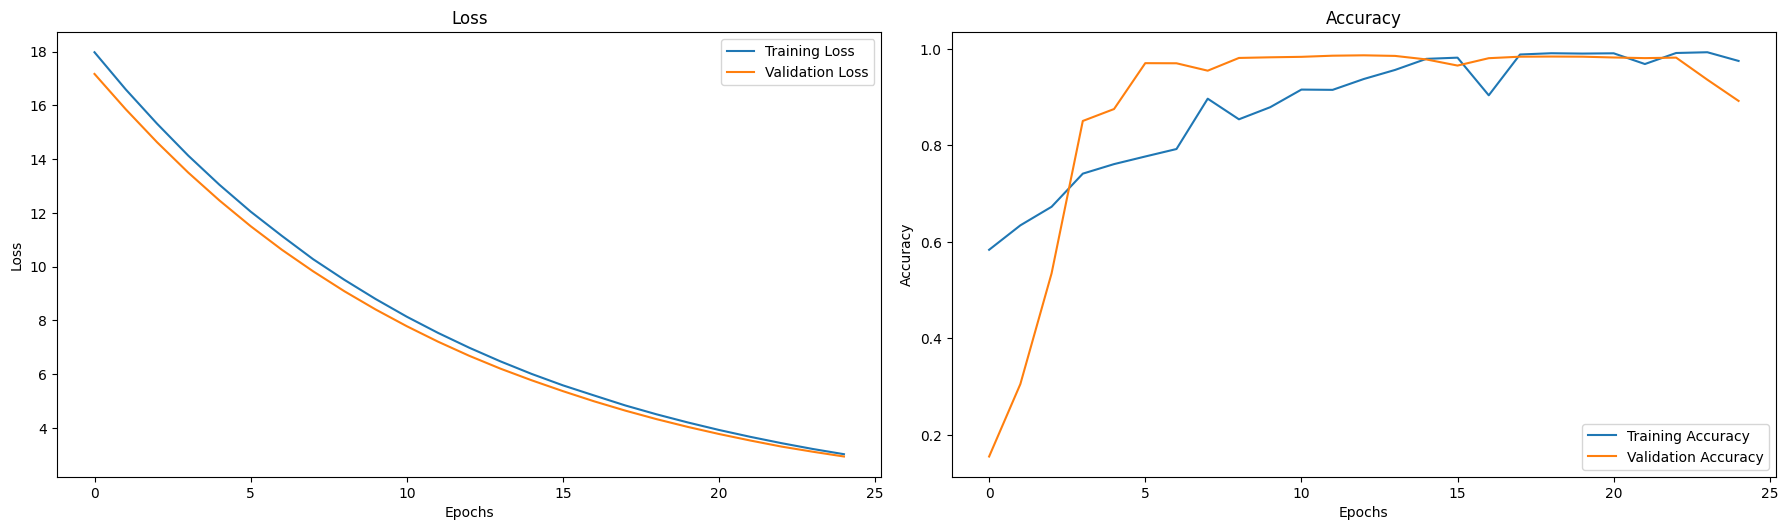

In [ ]:
def plot_training_history(history):
    plt.figure(figsize=(18, 10))

    plt.subplot(2, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(2, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history)


In [ ]:
# Calcul des métriques
from sklearn.metrics import confusion_matrix, recall_score, f1_score

val_predictions = model.predict(val_images)
val_predictions_binary = np.argmax(val_predictions, axis=-1)
val_masks_binary = np.argmax(val_masks, axis=-1)

# Fonction pour calculer les métriques
def evaluate_metrics(true_masks, pred_masks):
    true_masks = true_masks.flatten()
    pred_masks = pred_masks.flatten()

    cm = confusion_matrix(true_masks, pred_masks)
    recall = recall_score(true_masks, pred_masks)
    f1 = f1_score(true_masks, pred_masks)

    return cm, recall, f1

cm, recall, f1 = evaluate_metrics(val_masks, val_predictions_binary)
print(f'Confusion Matrix:\n{cm}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')

Confusion Matrix:
[[40565622  4551073]
 [  361484   134877]]
Recall: 0.27173166304363155
F1 Score: 0.052052838974735394


In [ ]:
# Palette de couleurs pour les masques prédits
def label_to_color(label):
    color_mask = np.zeros((label.shape[0], label.shape[1], 3))
    # Classe 0 (fond) en noir
    color_mask[label == 0] = [0, 0, 0]
    # Classe 1 (person) en rouge
    color_mask[label == 1] = [255, 0, 0]
    # Classe 2 (rider) en vert
    color_mask[label == 2] = [0, 255, 0]
    return color_mask

# Fonction d'affichage des résultats
def display_results(images, masks, predictions, num_images=20):
    plt.figure(figsize=(20, num_images * 5))
    for i in range(num_images):
        plt.subplot(num_images, 3, i*3 + 1)
        plt.imshow(images[i])
        plt.title('Image')

        plt.subplot(num_images, 3, i*3 + 2)
        plt.imshow(masks[i].squeeze(), cmap='gray')
        plt.title('Mask')

        plt.subplot(num_images, 3, i*3 + 3)
        color_pred = label_to_color(np.argmax(predictions[i], axis=-1))
        plt.imshow(color_pred)
        plt.title('Prediction')
    plt.show()

# Prédictions sur le jeu de validation
val_predictions = model.predict(np.array(val_images))
display_results(val_images, val_masks, val_predictions, num_images=20)

9/9 [==============================] - 42s 5s/step


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


In [ ]:

# Post-traitement
def post_process(predictions):
    processed_predictions = []
    for pred in predictions:
        pred = cv2.morphologyEx(pred.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        processed_predictions.append(pred)
    return np.array(processed_predictions)

# Évaluation du modèle
def evaluate_model(model, val_images, val_masks):
    val_predictions = model.predict(val_images)
    val_predictions = np.argmax(val_predictions, axis=-1).astype(np.uint8)

    val_predictions = post_process(val_predictions)

    val_masks_flat = val_masks.flatten()
    val_predictions_flat = val_predictions.flatten()

    f1 = f1_score(val_masks_flat, val_predictions_flat, average='binary')
    recall = recall_score(val_masks_flat, val_predictions_flat, average='binary')
    precision = precision_score(val_masks_flat, val_predictions_flat, average='binary')
    gmean = geometric_mean_score(val_masks_flat, val_predictions_flat, average='binary')

    print(f'F1 Score: {f1:.4f}')
    print(f'Recall: {recall:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'G-Mean: {gmean:.4f}')

In [ ]:
# Palette de couleurs pour les masques prédits
def label_to_color(label):
    color_mask = np.zeros((label.shape[0], label.shape[1], 3))
    # Classe 0 (fond) en noir
    color_mask[label == 0] = [0, 0, 0]
    # Classe 1 (person) en rouge
    color_mask[label == 1] = [255, 0, 0]
    # Classe 2 (rider) en vert
    color_mask[label == 2] = [0, 255, 0]
    return color_mask

# Fonction d'affichage des résultats
def display_results(images, masks, predictions, num_images=20):
    plt.figure(figsize=(20, num_images * 5))
    for i in range(num_images):
        plt.subplot(num_images, 3, i*3 + 1)
        plt.imshow(images[i])
        plt.title('Image')

        plt.subplot(num_images, 3, i*3 + 2)
        plt.imshow(masks[i].squeeze(), cmap='gray')
        plt.title('Mask')

        plt.subplot(num_images, 3, i*3 + 3)
        color_pred = label_to_color(np.argmax(predictions[i], axis=-1))
        plt.imshow(color_pred)
        plt.title('Prediction')
    plt.show()

# Prédictions sur le jeu de validation
val_predictions = model.predict(np.array(val_images))
val_predictions = post_process(val_predictions)
display_results(val_images, val_masks, val_predictions, num_images=20)

evaluate_model(model, val_images, val_masks)

9/9 [==============================] - 42s 5s/step


[Image retirée : elle reproduit des données Cityscapes, qui ne peuvent pas être redistribuées.]


9/9 [==============================] - 42s 5s/step
F1 Score: 0.0072
Recall: 0.0036
Precision: 0.3032
G-Mean: 0.0602
